In [21]:
from req_functions_from_ApproxSP import *
from tqdm import tqdm
import time
import pandas as pd
import json

In [22]:
## Two for One Code

import itertools
import copy

def generate_sw_manipulations(w_pref):
    """
    Sw: Move any two distinct men to top of w's list in any order.
    """
    manipulations = []
    for mi, mj in itertools.permutations(w_pref, 2): 
        rest = [m for m in w_pref if m != mi and m != mj]
        new_pref = [mi, mj] + rest
        manipulations.append(new_pref)
    return manipulations


def generate_sm_manipulations(m_pref, mu_m):
    """
    Sm: Promote µ(m) to top, then for every other woman, promote her to top of that list.
    """
    sm = []
    bm = [mu_m] + [w for w in m_pref if w != mu_m]
    sm.append(bm)

    for w0 in bm[1:]:  # exclude mu(m) which is already at the top
        manipulated = [w0] + [w for w in bm if w != w0]
        sm.append(manipulated)

    return sm


def two_for_one(mpref, wpref, accomplice, beneficiary):
    initial_matching = gale_shapley(mpref, wpref)
    mpref_prime = copy.deepcopy(mpref)
    wpref_prime = copy.deepcopy(wpref)
    best_matching = initial_matching

    accomplice_pref = mpref[accomplice - 1] 
    beneficiary_pref = wpref[beneficiary - 1]

    Sw = generate_sw_manipulations(beneficiary_pref)

    for w_misreport in Sw:
        t5 = time.perf_counter()

        Sm = generate_sm_manipulations(accomplice_pref, initial_matching[accomplice - 1])

        for m_misreport in Sm:
            t6 = time.perf_counter()
            mpref_prime[accomplice - 1] = m_misreport 
            wpref_prime[beneficiary - 1] = w_misreport
            new_matching = gale_shapley(mpref_prime, wpref_prime)

            new_w_pairing = new_matching[beneficiary - 1]
            new_m_pairing = new_matching[accomplice - 1]

            if beneficiary_pref.index(new_w_pairing) < beneficiary_pref.index(initial_matching[beneficiary - 1]) and initial_matching[accomplice - 1] == new_m_pairing:
                best_matching = new_matching
                accomplice_pref = m_misreport
                beneficiary_pref = w_misreport
                break
        t7 = time.perf_counter()
        #print(f"Time for t5 - t6: {t6 - t5:.4f} seconds")
        #print(f"Time for t6 - t7: {t7 - t6:.4f} seconds")
    return best_matching

In [23]:
import shutil

shutil.copyfile('euclidean_mallows_accomplice.csv', 'copy.csv')

'copy.csv'

In [27]:
df = pd.read_csv('copy.csv')
    
manipulable = []
df_subset = df.head(20)

for i, row in df_subset.iterrows():
    mpref = json.loads(row['mpref'])
    wpref = json.loads(row['wpref'])
    n = len(mpref)
    is_manipulable = False
    original_matching = gale_shapley(mpref, wpref)
    
    for accomplice in range(1, n + 1):
        for beneficiary in range(1, n+1):
            manipulated_matching = two_for_one(mpref, wpref, accomplice, beneficiary)
            if manipulated_matching != original_matching:
                is_manipulable = True
                break
        if is_manipulable:
            break

    manipulable.append(is_manipulable)

print(manipulable)

#df_subset['two_for_one_bool'] = manipulable

#counts = df.groupby(['phi_m', 'phi_w'])['two_for_one_bool'].sum()

#df.to_csv('copy.csv', index=False)

[True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]


In [ ]:
## Expectations Euclidean

data_EE = []
number_expectations_euclidean = []
number_EE_pairs = []
n = 30
std_list = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
d_list = [2, 4, 6, 8, 10]

for d in tqdm(d_list):
    number_d = []
    number_d_pairs = []
    for std in tqdm(std_list):
        count = []
        count_pairs = []
        ct = []
        for samples in range(500):
            count_woman = 0
            cnt_pairs = 0
            pref = generate_expectation_votes(n, d, 'uniform', std, 0.5)
            mpref = pref[0]
            wpref = pref[1]
            matching = gale_shapley(mpref, wpref)
            for manipulator in range (1, n+1):
                cnt = 0
                for accomplice in range (1, n+1):
                    result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
                    if result[0] != matching:
                        cnt += 1
                if cnt >= 1:
                    count_woman += 1
                    cnt_pairs += cnt
            count.append(count_woman)
            count_pairs.append(cnt_pairs)
            data_EE.append([d, std, json.dumps(convert_to_builtin(mpref)), json.dumps(convert_to_builtin(wpref)), samples, count_woman, cnt_pairs])
        if len(count) > 0:
            number_d.append(sum(count)/len(count))
            number_d_pairs.append(sum(count_pairs)/ len(count_pairs))
        else:
            number_d.append(0)
            number_d_pairs.append(0)
    number_expectations_euclidean.append(number_d)
    number_EE_pairs.append(number_d_pairs)
print(number_expectations_euclidean)
print(number_EE_pairs)

100%|██████████| 5/5 [26:34:52<00:00, 19138.47s/it]  

[[0.0, 2.262, 3.66, 3.0, 2.924, 2.626], [0.0, 0.378, 0.87, 1.206, 1.372, 1.502], [0.0, 0.304, 0.686, 0.86, 1.234, 1.312], [0.0, 0.26, 0.644, 0.992, 0.994, 1.068], [0.0, 0.192, 0.592, 0.842, 0.982, 1.012]]
[[0.0, 9.432, 20.312, 18.926, 16.492, 14.436], [0.0, 0.76, 2.894, 4.298, 5.844, 7.454], [0.0, 0.606, 1.914, 2.676, 5.334, 5.96], [0.0, 0.48, 1.638, 2.952, 3.378, 4.384], [0.0, 0.332, 1.424, 2.454, 3.268, 3.406]]


In [16]:
import csv
import json
from collections import defaultdict

data = []
euclidean_mallows_count = defaultdict(list)
rows = 2
start = time.perf_counter()
with open("euclidean_mallows_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  
    for i, row in enumerate(reader):
        if i >= rows:
            break
        phi1 = float(row[0])
        phi2 = float(row[1])
        mpref = json.loads(row[2])
        wpref = json.loads(row[3])
        samples = int(row[4])
        count_woman = int(row[5])
        cnt_pairs = int(row[6])
        data.append((phi1, phi2, mpref, wpref, samples, count_woman, cnt_pairs))
t1 = time.perf_counter()
print(f"Time for start to t1: {t1 - start:.4f} seconds")
for phi1, phi2, mpref, wpref, samples, count_woman, cnt_pairs in tqdm(data):
    t2 = time.perf_counter()
    print(f"Time for t1 - t2: {t2 - t1:.4f} seconds")
    success_count = 0
    original_matching = gale_shapley(mpref, wpref)
    for accomplice in range(1, len(mpref) + 1):
        t3 = time.perf_counter()
        print(f"Time for t2 - t3: {t3 - t2:.4f} seconds")
        for beneficiary in range(1, len(wpref) + 1):
            t4 = time.perf_counter()
            print(f"Time for t3 - t4: {t4 - t3:.4f} seconds")
            a_pref, b_pref, new_matching = two_for_one(mpref, wpref, accomplice, beneficiary)
            if new_matching != original_matching:
                success_count += 1
    end = time.perf_counter()
    
    print(f"Time for (phi1={phi1}, phi2={phi2}): {end - start:.4f} seconds")
    
    euclidean_mallows_count[(phi1, phi2)].append(success_count)

averages = {
    (phi1, phi2): sum(counts) / len(counts)
    for (phi1, phi2), counts in euclidean_mallows_count.items()}



Time for start to t1: 0.0011 seconds


  0%|          | 0/2 [00:00<?, ?it/s]

Time for t1 - t2: 0.0011 seconds
Time for t2 - t3: 0.0001 seconds
Time for t3 - t4: 0.0000 seconds
Time for t3 - t4: 1.3511 seconds
Time for t3 - t4: 2.6958 seconds
Time for t3 - t4: 4.0059 seconds
Time for t3 - t4: 5.3333 seconds
Time for t3 - t4: 6.6442 seconds
Time for t3 - t4: 7.9915 seconds
Time for t3 - t4: 9.3176 seconds
Time for t3 - t4: 10.6374 seconds
Time for t3 - t4: 11.9545 seconds
Time for t3 - t4: 13.2922 seconds
Time for t3 - t4: 14.6257 seconds
Time for t3 - t4: 15.9550 seconds
Time for t3 - t4: 17.3095 seconds
Time for t3 - t4: 18.6202 seconds
Time for t3 - t4: 19.9857 seconds
Time for t3 - t4: 21.3185 seconds
Time for t3 - t4: 22.6625 seconds
Time for t3 - t4: 24.0053 seconds
Time for t3 - t4: 25.3439 seconds
Time for t3 - t4: 26.6659 seconds
Time for t3 - t4: 27.9790 seconds
Time for t3 - t4: 29.3461 seconds
Time for t3 - t4: 30.6820 seconds
Time for t3 - t4: 32.0240 seconds
Time for t3 - t4: 33.3722 seconds
Time for t3 - t4: 34.6651 seconds
Time for t3 - t4: 36.040

 50%|█████     | 1/2 [3:22:01<3:22:01, 12121.19s/it]

Time for (phi1=0.0, phi2=0.0): 1188.2396 seconds
Time for t1 - t2: 1188.2391 seconds
Time for t2 - t3: 0.0001 seconds
Time for t3 - t4: 0.0000 seconds
Time for t3 - t4: 1.3538 seconds
Time for t3 - t4: 2.6499 seconds
Time for t3 - t4: 3.9560 seconds
Time for t3 - t4: 5.2525 seconds
Time for t3 - t4: 6.5445 seconds
Time for t3 - t4: 7.8632 seconds
Time for t3 - t4: 9.1594 seconds
Time for t3 - t4: 10.4487 seconds
Time for t3 - t4: 11.7504 seconds
Time for t3 - t4: 13.0374 seconds
Time for t3 - t4: 14.3247 seconds
Time for t3 - t4: 15.6102 seconds
Time for t3 - t4: 16.9214 seconds
Time for t3 - t4: 18.2016 seconds
Time for t3 - t4: 19.5202 seconds
Time for t3 - t4: 20.8242 seconds
Time for t3 - t4: 22.1135 seconds
Time for t3 - t4: 23.3996 seconds
Time for t3 - t4: 24.7025 seconds
Time for t3 - t4: 26.0183 seconds
Time for t3 - t4: 27.3201 seconds
Time for t3 - t4: 28.6137 seconds
Time for t3 - t4: 29.9150 seconds
Time for t3 - t4: 31.2036 seconds
Time for t3 - t4: 32.4907 seconds
Time f

 50%|█████     | 1/2 [3:23:50<3:23:50, 12230.02s/it]

Unexpected exception formatting exception. Falling back to standard exception



Traceback (most recent call last):
  File "/Users/annasophiakasehagen/Library/Python/3.11/lib/python/site-packages/IPython/core/interactiveshell.py", line 3549, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_55474/4208890619.py", line 36, in <module>
    a_pref, b_pref, new_matching = two_for_one(mpref, wpref, accomplice, beneficiary)
                                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/var/folders/w3/z2mywzxs2rb5b6k_0zt2rwbr0000gn/T/ipykernel_55474/2523606322.py", line 53, in two_for_one
    new_matching = gale_shapley(mpref_prime, wpref_prime)
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/annasophiakasehagen/Documents/Frontier SP & Stability/req_functions_from_ApproxSP.py", line None, in gale_shapley
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/

In [6]:
from euclidean import *
import json

data = []
numberEM_pairs = []
n=10
phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
for phi1 in tqdm(phi_list):
    number_phi_pairs = []
    for phi2 in tqdm(phi_list):
        count_pairs = []
        ct=[]
        for samples in range (1):
            cnt_pairs = 0
            pref=generate_mallows_euclidean_votes(n, phi1, phi2)
            mpref=pref[0]
            wpref=pref[1]
            matching = gale_shapley(mpref, wpref)
            for accomplice in range (1, n+1):
                cnt=0
                for beneficiary in range(1, n+1):
                    result = two_for_one(mpref, wpref, accomplice, beneficiary)
                    if result [2]!= matching:
                        cnt = cnt+1
                if cnt >= 1:
                    cnt_pairs += cnt
            count_pairs.append(cnt_pairs)
            data.append([phi1, phi2, json.dumps(mpref), json.dumps(wpref), samples, count_pairs])
        if len(count_pairs)>0:
            number_phi_pairs.append(sum(count_pairs) / len(count_pairs))
        else:
            number_phi_pairs.append(0)
    numberEM_pairs.append(number_phi_pairs)
print(numberEM_pairs)

100%|██████████| 6/6 [00:24<00:00,  4.09s/it]

[[15.0, 14.0, 6.0, 8.0, 0.0, 0.0], [13.0, 21.0, 0.0, 8.0, 9.0, 10.0], [14.0, 10.0, 9.0, 24.0, 24.0, 7.0], [16.0, 7.0, 0.0, 7.0, 16.0, 28.0], [21.0, 0.0, 15.0, 9.0, 23.0, 12.0], [16.0, 16.0, 8.0, 16.0, 5.0, 13.0]]


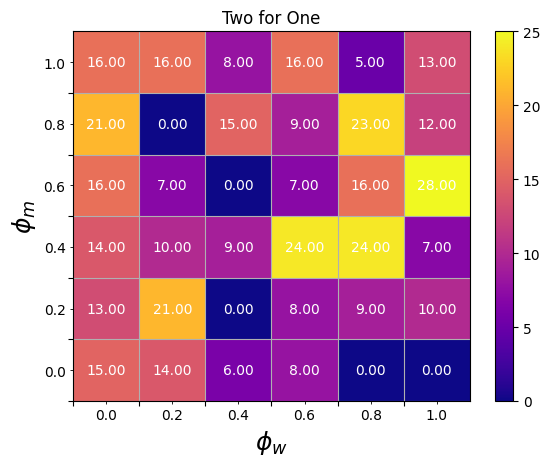

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

phi_list=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
    
w_number = np.array(numberEM_pairs)
# Create the pcolormesh plot

fig, ax = plt.subplots()

c = ax.pcolormesh(w_number, cmap='plasma', norm=mcolors.Normalize(vmin=0, vmax=25))
 
# Add color bar

fig.colorbar(c, ax=ax)
 
# Annotate each cell with the numeric value

for i in range(w_number.shape[0]):

    for j in range(w_number.shape[1]):

        ax.text(j + 0.5, i + 0.5, f'{w_number[i, j]:.2f}', 

                ha='center', va='center', color='white')
        

ax.set_xticks(np.arange(w_number.shape[1]))
ax.set_yticks(np.arange(w_number.shape[0]))

# Manually set the tick labels to be centered within each cell
ax.set_xticks(np.arange(w_number.shape[1]) + 0.5, minor=True)
ax.set_yticks(np.arange(w_number.shape[0]) + 0.5, minor=True)
ax.set_xticklabels(phi_list, minor=True)
ax.set_yticklabels(phi_list, minor=True)

# Hide the major tick labels
ax.set_xticklabels([], minor=False)
ax.set_yticklabels([], minor=False)

# Show minor ticks
ax.tick_params(axis='x', which='minor', bottom=True, top=False)
ax.tick_params(axis='y', which='minor', left=True, right=False)

plt.xlabel('$\phi_w$', fontsize=18)
plt.ylabel('$\phi_m$', fontsize=18)
plt.title('Two for One')
plt.grid(True)

plt.savefig("number_of_euclidean_mallows_pairs_two_for_one.pdf", format='pdf')
plt.show()